# Closed-loop DVFS energy evaluation on Jetson Orin NX

SmolVLA runs on the Jetson Orin NX and controls a Franka arm in Isaac Sim in **continuous mode**
(wall-clock pacing at 20 Hz; 50-action chunks, horizon 2.5 s). Each configuration pins CPU and GPU
frequencies (3 × 3 grid: min / mid / max of the device lists); `default` keeps the stock
governors (schedutil / nvhost_podgov) and serves as the reference.

Data: `outputs/dvfs_energy_evaluation/<RUN>/` written by `simulator/evaluate.py --dvfs-configs ... --energy`.

| Quantity | Definition |
|---|---|
| $E_\mathrm{comp}$ | ∫ VDD_IN dt over the active episode window (Jetson board input power) |
| $E_{\mathrm{inf},i}$, $L_i$ | Energy and server latency of inference $i$; EDP$_i = E_{\mathrm{inf},i} L_i$ |
| $E_\mathrm{mech}$ | Positive joint work ∫ Σ max(τ·q̇, 0) dt of joints 1–7 (simulation) |
| Success rate | Wilson 95 % CI; paired tests against `default` on identical (task, seed, episode) |

In [203]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from scipy import stats
from IPython.display import display

ROOT = Path.cwd()
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / 'outputs' / 'dvfs_energy_evaluation').is_dir())
RUN = 'grid3x3'
RUN_DIR = REPO / 'outputs' / 'dvfs_energy_evaluation' / RUN
FIG_DIR = ROOT / 'figures' / f'closed_loop_{RUN}'
OUT_DIR = ROOT / 'results' / f'closed_loop_{RUN}'
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'font.family': 'Times New Roman',
                     'font.sans-serif': ['Times New Roman', 'DejaVu Sans'],
                     'font.size': 15,
                     'axes.titlesize': 15,
                     'axes.labelsize': 15,
                     'xtick.labelsize': 15,
                     'ytick.labelsize': 15,
                     'legend.fontsize': 15,
                     'pdf.fonttype': 42,
                     'mathtext.fontset': 'stix',
                     'savefig.bbox': 'tight'})

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight')
    plt.show()

TASKS = ['grasping', 'pushing']
TASK_LABEL = {'grasping': 'Grasping', 'pushing': 'Pushing'}
TASK_COLOR = {'grasping': '#2a78d6', 'pushing': '#eb6834'}
REF = 'default'

exp_cfg = json.loads((RUN_DIR / 'experiment_config.json').read_text())
args = exp_cfg['arguments']
ep = pd.read_csv(RUN_DIR / 'episodes.csv')
req = pd.read_csv(RUN_DIR / 'inference_requests.csv')
switches = [json.loads(line) for line in (RUN_DIR / 'dvfs_switches.jsonl').read_text().splitlines() if line.strip()]
validation = json.loads((RUN_DIR / 'validation_report.json').read_text())
paired = pd.read_csv(RUN_DIR / 'paired_tests.csv')
horizon_tab = pd.read_csv(RUN_DIR / 'latency_horizon_analysis.csv')

CONTROL_HZ = exp_cfg['policy_health']['contract']['fps']
CHUNK = 50
HORIZON_MS = 1000 * CHUNK / CONTROL_HZ

print('Run:', RUN, '| experiment', exp_cfg['experiment_id'])
print(json.dumps({k: args[k] for k in ['mode', 'task', 'seeds', 'episodes', 'execute_steps', 'prefetch',
                                       'timeout', 'dvfs_settle_s', 'dvfs_warmup', 'actuator_model']}))
print(f'Episodes: {len(ep)} | inference requests: {len(req)} | chunk horizon {HORIZON_MS:.0f} ms')

Run: grid3x3 | experiment 20261107T211451Z_b92be4
{"mode": "continuous", "task": "both", "seeds": [41, 42, 43, 44, 45], "episodes": 3, "execute_steps": 25, "prefetch": 20, "timeout": 30.0, "dvfs_settle_s": 2.0, "dvfs_warmup": 3, "actuator_model": null}
Episodes: 300 | inference requests: 3577 | chunk horizon 2500 ms


## 1. Configurations and data integrity

In [204]:
# Grid coordinates per configuration (default has no pinned frequency).
def config_freqs(df):
    g = df.groupby('configuration')[['cpu_mhz_requested', 'gpu_mhz_requested']].first()
    return g.rename(columns={'cpu_mhz_requested': 'cpu_mhz', 'gpu_mhz_requested': 'gpu_mhz'})

freqs = config_freqs(ep)
grid = freqs.dropna().sort_values(['cpu_mhz', 'gpu_mhz'])
CONFIGS = [REF] + list(grid.index)
cpu_order = np.sort(grid.cpu_mhz.unique())
gpu_order = np.sort(grid.gpu_mhz.unique())

def short_label(c):
    if c == REF:
        return 'Default'
    return f"{freqs.loc[c, 'cpu_mhz']:.0f}/{freqs.loc[c, 'gpu_mhz']:.0f}"

print('CPU levels (MHz):', cpu_order, '| GPU levels (MHz):', gpu_order)
display(ep.groupby(['configuration', 'task']).size().unstack().reindex(CONFIGS))
assert ep.groupby(['configuration', 'task']).size().nunique() == 1, 'unbalanced design'
assert not ep.duplicated(['configuration', 'task', 'seed', 'episode']).any()

# DVFS read-back at each switch (one switch before every episode; sysfs after the settle period).
sw = pd.DataFrame([{
    'configuration': s['name'],
    'cpu_readback_mhz': max(s['cpu_khz']) / 1000,
    'gpu_readback_mhz': s['gpu_hz'] / 1e6,
    'emc_mhz': s['emc_hz'] / 1e6,
    'governor': f"{s['cpu_governors'][0]} / {s['gpu_governor']}",
    'warmup_ms': np.median(s['warmup_ms']),
    'tj_temp_c': s['temps_c'].get('tj-thermal'),
    'valid': s['frequency_valid'],
} for s in switches])
sw_summary = sw.groupby('configuration').agg(
    switches=('valid', 'size'), all_valid=('valid', 'all'), governor=('governor', 'first'),
    cpu_readback_mhz=('cpu_readback_mhz', lambda s: '/'.join(f'{v:.0f}' for v in sorted(s.unique()))),
    gpu_readback_mhz=('gpu_readback_mhz', lambda s: '/'.join(f'{v:.0f}' for v in sorted(s.unique()))),
    emc_mhz=('emc_mhz', 'median'), warmup_ms_median=('warmup_ms', 'median'),
    tj_temp_c_mean=('tj_temp_c', 'mean')).reindex(CONFIGS)
print('Power mode:', sorted({s['power_mode'] for s in switches}))
display(sw_summary.round(1))

# Frequencies sampled during the episodes (the default governor moves them).
fr = ep.groupby('configuration').agg(cpu_mean=('cpu_mhz_actual', 'mean'), cpu_min=('cpu_mhz_min', 'min'),
                                     cpu_max=('cpu_mhz_max', 'max'), gpu_mean=('gpu_mhz_actual', 'mean'),
                                     gpu_min=('gpu_mhz_min', 'min'), gpu_max=('gpu_mhz_max', 'max'),
                                     stable=('frequency_stable', 'mean'), rtf_min=('real_time_factor', 'min'),
                                     rtf_max=('real_time_factor', 'max'), tj_end_c=('soc_temp_end_c', 'mean'))
display(fr.reindex(CONFIGS).round(3))

chk = pd.DataFrame(validation['checks'])
print(f"Validation: passed={validation['passed']} | {chk.passed.sum()}/{len(chk)} checks passed")
print('Actuator model:', validation['actuator_model'])
display(chk.loc[~chk.passed, ['check', 'severity', 'detail']])

CPU levels (MHz): [ 115.2 1036.8 1984. ] | GPU levels (MHz): [306. 612. 918.]


task,grasping,pushing
configuration,,
default,15,15
cpu115.2_gpu306,15,15
cpu115.2_gpu612,15,15
cpu115.2_gpu918,15,15
cpu1036.8_gpu306,15,15
cpu1036.8_gpu612,15,15
cpu1036.8_gpu918,15,15
cpu1984_gpu306,15,15
cpu1984_gpu612,15,15


Power mode: ['NV Power Mode: MAXN / 0']


,switches,all_valid,governor,cpu_readback_mhz,gpu_readback_mhz,emc_mhz,warmup_ms_median,tj_temp_c_mean
configuration,,,,,,,,
default,30,True,schedutil / nvhost_podgov,1190/1267/1344/1984,306,2133.0,880.4,50.7
cpu115.2_gpu306,30,True,userspace / userspace,115,306,2133.0,11626.4,50.7
cpu115.2_gpu612,30,True,userspace / userspace,115,612,2133.0,11869.3,50.4
cpu115.2_gpu918,30,True,userspace / userspace,115,918,2133.0,11786.3,50.2
cpu1036.8_gpu306,30,True,userspace / userspace,1037,306,2133.0,1489.8,50.2
cpu1036.8_gpu612,30,True,userspace / userspace,1037,612,2133.0,1403.7,50.2
cpu1036.8_gpu918,30,True,userspace / userspace,1037,918,2133.0,1320.4,50.3
cpu1984_gpu306,30,True,userspace / userspace,1984,306,2133.0,878.6,50.4
cpu1984_gpu612,30,True,userspace / userspace,1984,612,2133.0,802.4,50.6


,cpu_mean,cpu_min,cpu_max,gpu_mean,gpu_min,gpu_max,stable,rtf_min,rtf_max,tj_end_c
configuration,,,,,,,,,,
default,1069.27,115.2,1984.0,319.284,306.0,612.0,NaN,0.996,1.0,50.835
cpu115.2_gpu306,115.20,115.2,115.2,306.000,306.0,306.0,1.0,1.000,1.0,50.273
cpu115.2_gpu612,115.20,115.2,115.2,612.000,612.0,612.0,1.0,1.000,1.0,50.205
cpu115.2_gpu918,115.20,115.2,115.2,918.000,918.0,918.0,1.0,1.000,1.0,50.289
cpu1036.8_gpu306,1036.80,1036.8,1036.8,306.000,306.0,306.0,1.0,0.997,1.0,50.260
cpu1036.8_gpu612,1036.80,1036.8,1036.8,612.000,612.0,612.0,1.0,0.997,1.0,50.291
cpu1036.8_gpu918,1036.80,1036.8,1036.8,918.000,918.0,918.0,1.0,0.997,1.0,50.510
cpu1984_gpu306,1984.00,1984.0,1984.0,306.000,306.0,306.0,1.0,0.996,1.0,50.781
cpu1984_gpu612,1984.00,1984.0,1984.0,612.000,612.0,612.0,1.0,0.996,1.0,50.915


Validation: passed=True | 31/32 checks passed
Actuator model: not configured (--actuator-model not given)


,check,severity,detail
31,joint effort is the simulated joint load (inve...,warning,"relative residual [1.18, 0.0]; corr (joints > ..."


## 2. Per-configuration summary

Success rate pooled over both tasks and per task (Wilson 95 % CI, seed-level SD over 5 seeds).
Latency and inference energy are per request; $E_\mathrm{comp}$ and $E_\mathrm{mech}$ are per episode.
Energy per success = Σ energy / number of successes (NaN when there is no success).

In [205]:
def wilson(k, n, z=1.959964):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return max(0.0, centre - half), min(1.0, centre + half)

def summarise(e, r):
    k, n = int(e.success.sum()), len(e)
    lo, hi = wilson(k, n)
    seed_sr = e.groupby('seed').success.mean()
    ok = e[e.success.astype(bool)]
    return pd.Series({
        'episodes': n, 'successes': k,
        'success_pct': 100 * k / n, 'success_lo_pct': 100 * lo, 'success_hi_pct': 100 * hi,
        'success_seed_sd_pct': 100 * seed_sr.std(ddof=1),
        'inference_ms': r.inference_ms.mean(), 'inference_ms_p95': r.inference_ms.quantile(.95),
        'rtt_ms': r.rtt_ms.mean(), 'communication_ms': r.communication_ms.mean(),
        'obs_to_action_ms': r.obs_to_action_ms.mean(),
        'requests_over_horizon_pct': 100 * r.exceeds_horizon.mean(),
        'power_w': e.computational_power_w.mean(),
        'E_comp_j': e.computational_energy_j.mean(), 'E_comp_sd_j': e.computational_energy_j.std(ddof=1),
        'E_inf_j': r.inference_energy_j.mean(), 'EDP_js': r.inference_edp_js.mean(),
        'E_mech_j': e.mechanical_energy_j.mean(),
        'E_comp_per_success_j': e.computational_energy_j.sum() / k if k else np.nan,
        'E_mech_per_success_j': e.mechanical_energy_j.sum() / k if k else np.nan,
        'underrun_pct': 100 * e.buffer_underrun_rate.mean(),
        'initial_wait_s': e.initial_wait_s.mean(),
        'episode_s': e.episode_duration_s.mean(),
        'completion_s': ok.completion_time_s.mean() if len(ok) else np.nan,
        'ajj': e.ajj.mean(),
    })

def summary_table(by_task):
    rows = []
    keys = ['configuration', 'task'] if by_task else ['configuration']
    for key, e in ep.groupby(keys):
        key = key if isinstance(key, tuple) else (key,)
        mask = np.ones(len(req), bool)
        for col, val in zip(keys, key):
            mask &= (req[col] == val).to_numpy()
        rows.append(pd.concat([pd.Series(dict(zip(keys, key))), summarise(e, req[mask])]))
    out = pd.DataFrame(rows)
    out['configuration'] = pd.Categorical(out.configuration, CONFIGS, ordered=True)
    out = out.sort_values(keys).reset_index(drop=True)
    out.insert(1, 'cpu_mhz', out.configuration.astype(str).map(freqs.cpu_mhz))
    out.insert(2, 'gpu_mhz', out.configuration.astype(str).map(freqs.gpu_mhz))
    return out

per_config = summary_table(by_task=False)
per_task = summary_table(by_task=True)
per_config.to_csv(OUT_DIR / 'per_config_summary.csv', index=False)
per_task.to_csv(OUT_DIR / 'per_task_summary.csv', index=False)

show = ['configuration', 'success_pct', 'success_lo_pct', 'success_hi_pct', 'inference_ms', 'rtt_ms',
        'requests_over_horizon_pct', 'power_w', 'E_comp_j', 'E_inf_j', 'EDP_js', 'E_mech_j',
        'E_comp_per_success_j', 'underrun_pct', 'completion_s']
display(per_config[show].round(2))
display(per_task.pivot(index='configuration', columns='task',
                       values=['success_pct', 'E_comp_per_success_j', 'completion_s'])
        .reindex(CONFIGS).round(1))

,configuration,success_pct,success_lo_pct,success_hi_pct,inference_ms,rtt_ms,requests_over_horizon_pct,power_w,E_comp_j,E_inf_j,EDP_js,E_mech_j,E_comp_per_success_j,underrun_pct,completion_s
0,default,50.00,33.15,66.85,992.27,1202.04,0.23,7.15,144.08,7.26,7.25,31.86,288.16,18.64,10.26
1,cpu115.2_gpu306,0.00,0.00,11.35,11804.70,12038.70,100.00,5.21,156.27,61.43,725.58,4.66,NaN,100.00,NaN
2,cpu115.2_gpu612,0.00,0.00,11.35,11868.47,12115.41,100.00,5.46,163.69,64.72,768.79,4.66,NaN,100.00,NaN
3,cpu115.2_gpu918,0.00,0.00,11.35,11805.57,12067.34,100.00,6.06,181.85,71.54,845.18,4.66,NaN,100.00,NaN
4,cpu1036.8_gpu306,10.00,3.46,25.62,1502.41,1656.91,0.81,6.04,170.99,9.17,13.78,42.05,1709.90,55.09,12.92
5,cpu1036.8_gpu612,20.00,9.51,37.31,1413.84,1577.86,0.62,6.31,167.59,9.02,12.76,44.20,837.94,48.02,12.87
6,cpu1036.8_gpu918,26.67,14.18,44.45,1328.73,1510.33,1.25,7.10,179.17,9.57,12.72,43.26,671.89,40.90,12.21
7,cpu1984_gpu306,46.67,30.23,63.86,882.45,1081.76,0.00,7.53,155.74,6.89,6.08,28.58,333.74,10.38,10.04
8,cpu1984_gpu612,53.33,36.14,69.77,809.46,1016.29,0.00,7.87,153.08,6.66,5.39,27.58,287.02,7.09,10.18
9,cpu1984_gpu918,43.33,27.38,60.80,787.98,1013.73,0.60,8.21,175.64,6.78,5.34,31.62,405.33,7.27,10.16


success_pct         E_comp_per_success_j          \
task                grasping pushing             grasping pushing   
configuration                                                       
default                 73.3    26.7                149.1   670.6   
cpu115.2_gpu306          0.0     0.0                  NaN     NaN   
cpu115.2_gpu612          0.0     0.0                  NaN     NaN   
cpu115.2_gpu918          0.0     0.0                  NaN     NaN   
cpu1036.8_gpu306         0.0    20.0                  NaN   804.2   
cpu1036.8_gpu612         0.0    40.0                  NaN   365.7   
cpu1036.8_gpu918         0.0    53.3                  NaN   272.9   
cpu1984_gpu306          80.0    13.3                131.5  1547.2   
cpu1984_gpu612          80.0    26.7                137.4   735.9   
cpu1984_gpu918          60.0    26.7                243.6   769.2   

                 completion_s          
task                 grasping pushing  
configuration                          
default                  10.0    11.0  
cpu115.2_gpu306           NaN     NaN  
cpu115.2_gpu612           NaN     NaN  
cpu115.2_gpu918           NaN     NaN  
cpu1036.8_gpu306          NaN    12.9  
cpu1036.8_gpu612          NaN    12.9  
cpu1036.8_gpu918          NaN    12.2  
cpu1984_gpu306           10.0    10.5  
cpu1984_gpu612            9.9    10.9  
cpu1984_gpu918            9.8    10.9

## 3. CPU × GPU heatmaps

Same layout as `data_analysis_1` (x: CPU, y: GPU). The 115.2 MHz CPU row is an order of magnitude
slower, so latency, inference energy and EDP use a **logarithmic** colour scale. The value of the
default governor is given under each panel title. The first figure is the success rate per
[CPU, GPU] combination: (a) grasping, (b) pushing (15 episodes per cell). The second figure is the
mean total energy $E_\mathrm{total} = E_\mathrm{comp} + E_\mathrm{mech}$ of **successful episodes only**
("--": no success). No actuator electrical model is configured, so $E_\mathrm{mech}$ is the positive
joint work at the joints, not the electrical input of the motors.

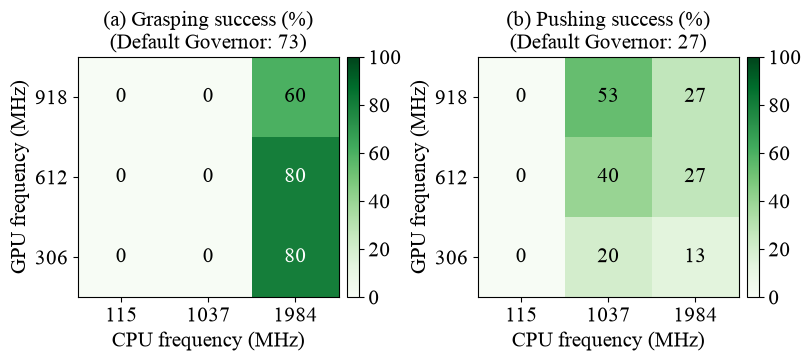

task,grasping,pushing
configuration,,
default,73.3,26.7
cpu115.2_gpu306,0.0,0.0
cpu115.2_gpu612,0.0,0.0
cpu115.2_gpu918,0.0,0.0
cpu1036.8_gpu306,0.0,20.0
cpu1036.8_gpu612,0.0,40.0
cpu1036.8_gpu918,0.0,53.3
cpu1984_gpu306,80.0,13.3
cpu1984_gpu612,80.0,26.7


In [ ]:
def grid_matrix(table, metric):
    mat = table.dropna(subset=['cpu_mhz']).pivot(index='gpu_mhz', columns='cpu_mhz', values=metric)
    return mat.reindex(index=gpu_order, columns=cpu_order)

def plot_heatmap(ax, table, metric, title, cmap, fmt, log=False, vlim=None, ref_value=True, nan_text='n/a'):
    mat = grid_matrix(table, metric)
    vals = np.ma.masked_invalid(mat.values.astype(float))
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad('#e6e6e6')
    if log:
        norm = LogNorm(vmin=np.nanmin(mat.values), vmax=np.nanmax(mat.values))
    else:
        lo, hi = vlim if vlim else (np.nanmin(mat.values), np.nanmax(mat.values))
        norm = plt.Normalize(lo, hi)
    im = ax.imshow(vals, origin='lower', aspect='auto', cmap=cm, norm=norm)
    ax.set_xticks(range(len(cpu_order)))
    ax.set_xticklabels([f'{v:.0f}' for v in cpu_order])
    ax.set_yticks(range(len(gpu_order)))
    ax.set_yticklabels([f'{v:.0f}' for v in gpu_order])
    ax.set_xlabel('CPU frequency (MHz)', fontsize=15)
    ax.set_ylabel('GPU frequency (MHz)', fontsize=15)
    if ref_value:
        ref = table.loc[table.configuration == REF, metric]
        if len(ref) == 1:
            rv = ref.iloc[0]
            title = f"{title}"
    ax.set_title(title, fontsize=15)
    for j in range(len(gpu_order)):
        for i in range(len(cpu_order)):
            val = mat.values[j, i]
            if pd.isna(val):
                ax.text(i, j, nan_text, fontsize=15, ha='center', va='center', color='#555555')
            else:
                ax.text(i, j, format(val, fmt), fontsize=15, ha='center', va='center',
                        color='white' if norm(val) > 0.60 else 'black')
    ax.figure.colorbar(im, ax=ax, fraction=.046, pad=.03)

# Success rate per [CPU, GPU] and task: (a) grasping, (b) pushing.
fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')
for ax, (label, task) in zip(axs, zip('ab', TASKS)):
    plot_heatmap(ax, per_task[per_task.task == task], 'success_pct',
                 f'({label}) {TASK_LABEL[task]} success (%)', 'Greens', '.0f', vlim=(0, 100))
save_figure(fig, 'fig_cl_success_by_task')

display(per_task.pivot(index='configuration', columns='task', values='success_pct').reindex(CONFIGS).round(1))

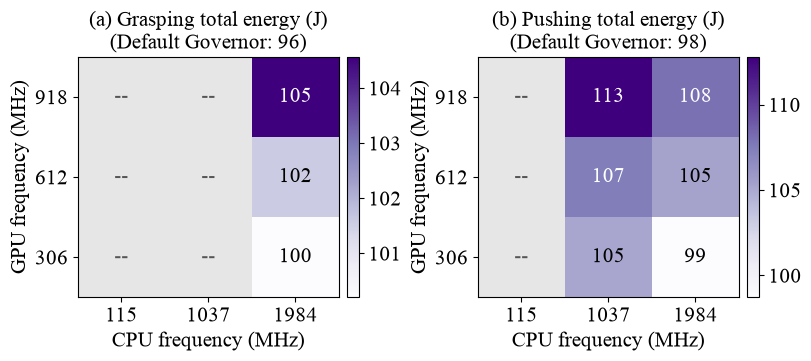

n_success         E_total_success_j         E_comp_success_j  \
task              grasping pushing          grasping pushing         grasping   
configuration                                                                   
default               11.0     4.0              96.3    97.7             71.3   
cpu115.2_gpu306        0.0     0.0               NaN     NaN              NaN   
cpu115.2_gpu612        0.0     0.0               NaN     NaN              NaN   
cpu115.2_gpu918        0.0     0.0               NaN     NaN              NaN   
cpu1036.8_gpu306       0.0     3.0               NaN   105.1              NaN   
cpu1036.8_gpu612       0.0     6.0               NaN   107.5              NaN   
cpu1036.8_gpu918       0.0     8.0               NaN   112.8              NaN   
cpu1984_gpu306        12.0     2.0             100.2    98.7             75.2   
cpu1984_gpu612        12.0     4.0             101.6   105.3             78.4   
cpu1984_gpu918         9.0     4.0             104.6   108.0             80.9   

                         E_mech_success_j          
task             pushing         grasping pushing  
configuration                                      
default             79.4             24.9    18.3  
cpu115.2_gpu306      NaN              NaN     NaN  
cpu115.2_gpu612      NaN              NaN     NaN  
cpu115.2_gpu918      NaN              NaN     NaN  
cpu1036.8_gpu306    78.3              NaN    26.8  
cpu1036.8_gpu612    81.4              NaN    26.0  
cpu1036.8_gpu918    87.1              NaN    25.7  
cpu1984_gpu306      79.7             25.0    19.0  
cpu1984_gpu612      85.8             23.2    19.6  
cpu1984_gpu918      90.3             23.7    17.7

In [207]:
# Total energy per successful episode: E_total = E_comp (Jetson VDD_IN) + E_mech (positive joint work).
# Only successful episodes enter the mean; cells with SR = 0 are shown as "--".
ok = ep[ep.success.astype(bool)].assign(E_total_j=lambda d: d.computational_energy_j + d.mechanical_energy_j)
succ_energy = (ok.groupby(['configuration', 'task'])
                 .agg(n_success=('E_total_j', 'size'), E_total_success_j=('E_total_j', 'mean'),
                      E_total_success_sd_j=('E_total_j', 'std'),
                      E_comp_success_j=('computational_energy_j', 'mean'),
                      E_mech_success_j=('mechanical_energy_j', 'mean'))
                 .reset_index())
key = per_task.configuration.astype(str) + '|' + per_task.task
succ_energy.index = succ_energy.configuration + '|' + succ_energy.task
for col in ['n_success', 'E_total_success_j', 'E_total_success_sd_j', 'E_comp_success_j', 'E_mech_success_j']:
    per_task[col] = key.map(succ_energy[col]).to_numpy()
per_task['n_success'] = per_task.n_success.fillna(0).astype(int)
per_task.to_csv(OUT_DIR / 'per_task_summary.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')
for ax, (label, task) in zip(axs, zip('ab', TASKS)):
    plot_heatmap(ax, per_task[per_task.task == task], 'E_total_success_j',
                 f'({label}) {TASK_LABEL[task]} total energy (J)', 'Purples', '.0f', nan_text='--')
save_figure(fig, 'fig_cl_total_energy_success')

display(per_task.pivot(index='configuration', columns='task',
                       values=['n_success', 'E_total_success_j', 'E_comp_success_j', 'E_mech_success_j'])
        .reindex(CONFIGS).round(1))

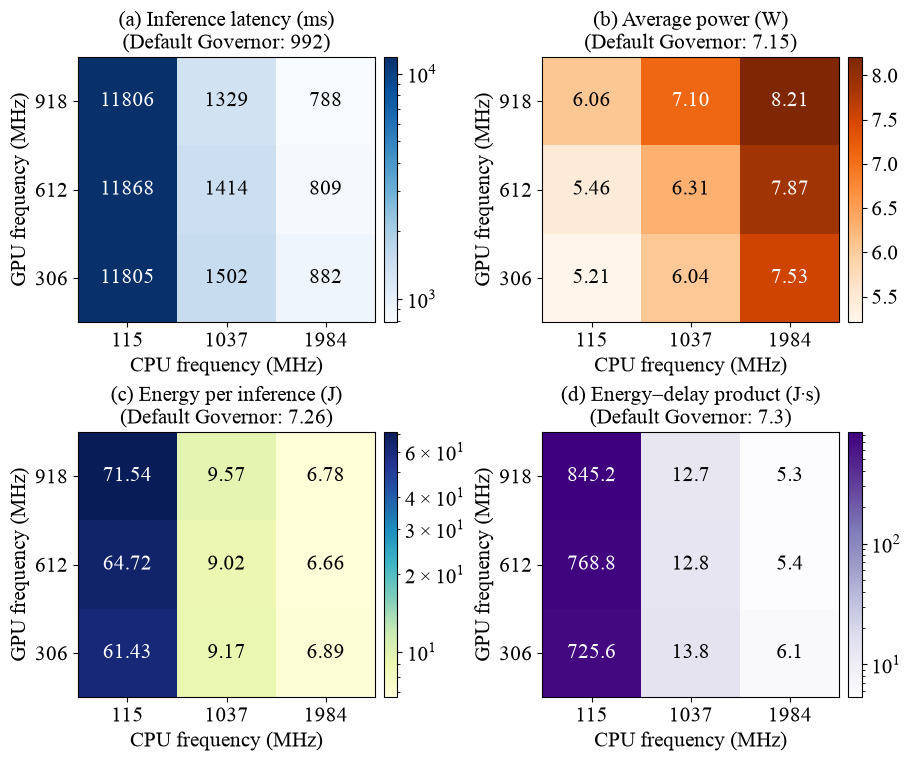

In [208]:
specs = [('inference_ms', '(a) Inference latency (ms)', 'Blues', '.0f', True),
         ('power_w', '(b) Average power (W)', 'Oranges', '.2f', False),
         ('E_inf_j', '(c) Energy per inference (J)', 'YlGnBu', '.2f', True),
         ('EDP_js', '(d) Energy–delay product (J·s)', 'Purples', '.1f', True)]
fig, axs = plt.subplots(2, 2, figsize=(9, 7.5), layout='constrained')
for ax, (met, ttl, cmap, fmt, log) in zip(axs.flat, specs):
    plot_heatmap(ax, per_config, met, ttl, cmap, fmt, log=log)
save_figure(fig, 'fig_cl_inference_heatmaps')

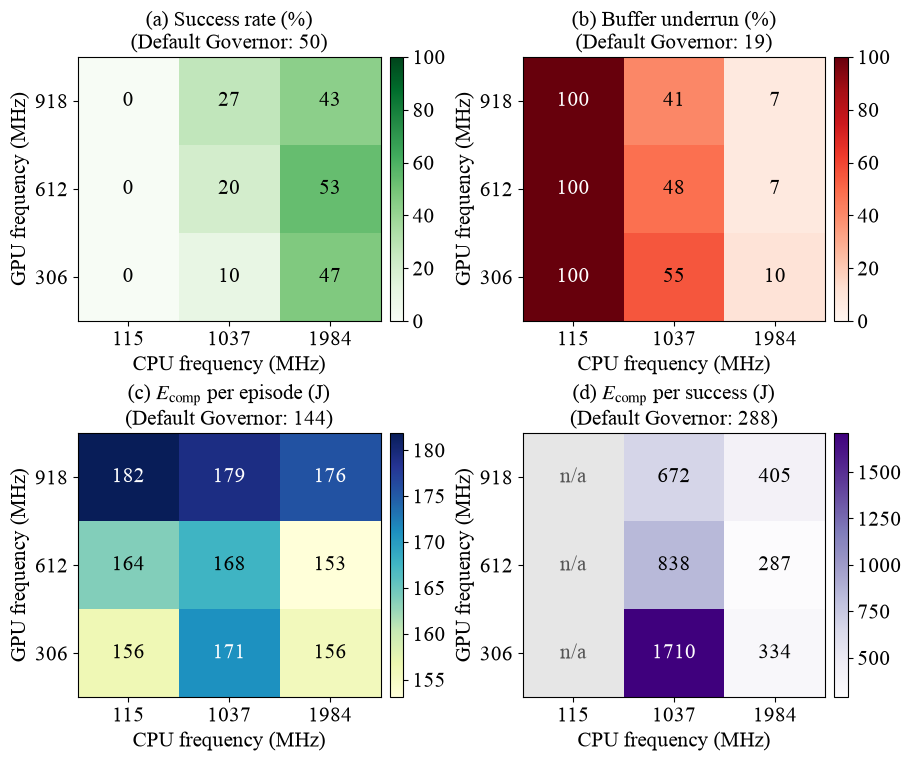

In [209]:
specs = [('success_pct', '(a) Success rate (%)', 'Greens', '.0f', (0, 100)),
         ('underrun_pct', '(b) Buffer underrun (%)', 'Reds', '.0f', (0, 100)),
         ('E_comp_j', '(c) $E_\\mathrm{comp}$ per episode (J)', 'YlGnBu', '.0f', None),
         ('E_comp_per_success_j', '(d) $E_\\mathrm{comp}$ per success (J)', 'Purples', '.0f', None)]
fig, axs = plt.subplots(2, 2, figsize=(9, 7.5), layout='constrained')
for ax, (met, ttl, cmap, fmt, vlim) in zip(axs.flat, specs):
    plot_heatmap(ax, per_config, met, ttl, cmap, fmt, vlim=vlim)
save_figure(fig, 'fig_cl_task_energy_heatmaps')

## 4. Latency, action timing and task success

Continuous mode keeps the arm moving on the previous chunk while the next one is computed; a chunk
arriving after its observation is $d$ ticks old has its first $d$ actions dropped. When inference
exceeds the 2.5 s horizon the queue runs dry and the arm holds its last target.

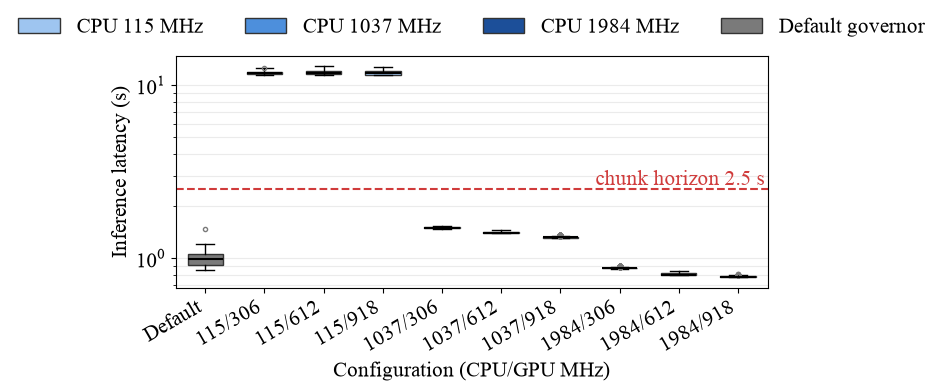

In [210]:
cpu_ramp = dict(zip(cpu_order, ['#9ec5f0', '#4d8fdc', '#1c4f99']))
def config_color(c):
    return '#7a7a7a' if c == REF else cpu_ramp[freqs.loc[c, 'cpu_mhz']]

fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
data = [req.loc[req.configuration == c, 'inference_ms'].to_numpy() / 1000 for c in CONFIGS]
bp = ax.boxplot(data, widths=.6, patch_artist=True, showfliers=True,
                flierprops=dict(marker='o', markersize=3, markerfacecolor='none', markeredgecolor='#7a7a7a'),
                medianprops=dict(color='black', linewidth=1.5))
for patch, c in zip(bp['boxes'], CONFIGS):
    patch.set_facecolor(config_color(c)); patch.set_edgecolor('#333333')
ax.axhline(HORIZON_MS / 1000, color='#d03b3b', ls='--', lw=1.5)
ax.text(len(CONFIGS) + .45, HORIZON_MS / 1000, 'chunk horizon 2.5 s', color='#d03b3b',
        ha='right', va='bottom', fontsize=15)
ax.set_yscale('log')
ax.set_xticks(range(1, len(CONFIGS) + 1))
ax.set_xticklabels([short_label(c) for c in CONFIGS], rotation=30, ha='right')
ax.set_xlabel('Configuration (CPU/GPU MHz)')
ax.set_ylabel('Inference latency (s)')
ax.grid(axis='y', which='both', alpha=.25)
ax.legend([plt.Rectangle((0, 0), 1, 1, fc=cpu_ramp[c], ec='#333333') for c in cpu_order]
          + [plt.Rectangle((0, 0), 1, 1, fc='#7a7a7a', ec='#333333')],
          [f'CPU {c:.0f} MHz' for c in cpu_order] + ['Default governor'],
          ncol=4, loc='lower center', bbox_to_anchor=(.5, 1.0), frameon=False)
save_figure(fig, 'fig_cl_latency_box')

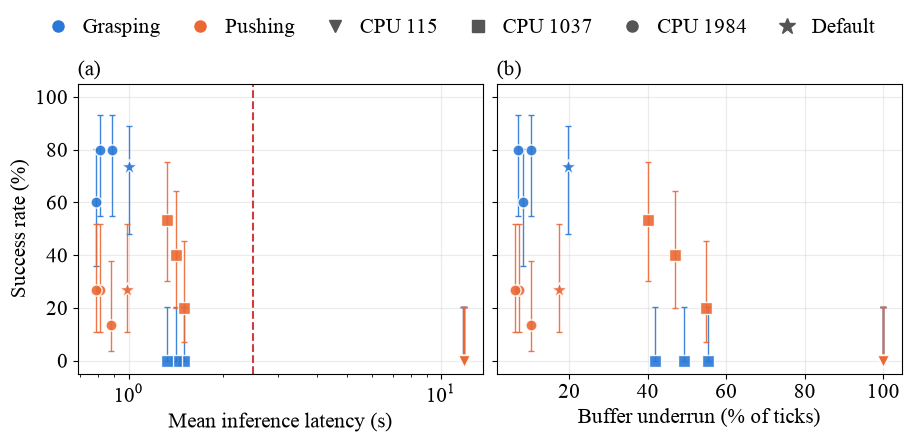

,task,group,episodes,successes,success_rate_pct,success_ci95_low_pct,success_ci95_high_pct,underrun_rate_mean,holding_time_s_mean,rho
0,grasping,all requests <= horizon,95,43.0,45.263,35.633,55.262,0.252,7.582,NaN
1,grasping,some requests > horizon,10,1.0,10.000,1.788,40.415,0.479,14.435,NaN
2,grasping,all requests > horizon,45,0.0,0.000,0.000,7.865,1.000,30.000,NaN
3,grasping,"spearman(inference_ms_mean, buffer_underrun_rate)",150,NaN,NaN,NaN,NaN,NaN,NaN,0.950
4,grasping,"spearman(inference_ms_mean, success)",150,NaN,NaN,NaN,NaN,NaN,NaN,-0.573
5,pushing,all requests <= horizon,103,31.0,30.097,22.086,39.539,0.254,7.027,NaN
6,pushing,some requests > horizon,2,0.0,0.000,0.000,65.762,0.626,19.600,NaN
7,pushing,all requests > horizon,45,0.0,0.000,0.000,7.865,1.000,30.000,NaN
8,pushing,"spearman(inference_ms_mean, buffer_underrun_rate)",150,NaN,NaN,NaN,NaN,NaN,NaN,0.959
9,pushing,"spearman(inference_ms_mean, success)",150,NaN,NaN,NaN,NaN,NaN,NaN,-0.136


In [211]:
# Success rate against the observation-to-action delay (per configuration and task).
CPU_MARKER = dict(zip(cpu_order, ['v', 's', 'o']))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8), layout='constrained', sharey=True)
for ax, xcol, xlabel, label in [(axs[0], 'inference_ms', 'Mean inference latency (s)', '(a)'),
                                (axs[1], 'underrun_pct', 'Buffer underrun (% of ticks)', '(b)')]:
    for task in TASKS:
        t = per_task[per_task.task == task]
        for _, row in t.iterrows():
            c = str(row.configuration)
            x = row[xcol] / 1000 if xcol == 'inference_ms' else row[xcol]
            yerr = [[row.success_pct - row.success_lo_pct], [row.success_hi_pct - row.success_pct]]
            marker = '*' if c == REF else CPU_MARKER[row.cpu_mhz]
            ax.errorbar(x, row.success_pct, yerr=yerr, fmt=marker, ms=12 if c == REF else 8,
                        color=TASK_COLOR[task], mec='white', mew=1, elinewidth=1, capsize=2, alpha=.9)
    if xcol == 'inference_ms':
        ax.set_xscale('log')
        ax.axvline(HORIZON_MS / 1000, color='#d03b3b', ls='--', lw=1.5)
    ax.set_xlabel(xlabel)
    ax.set_title(label, loc='left')
    ax.grid(alpha=.25)
axs[0].set_ylabel('Success rate (%)')
axs[0].set_ylim(-5, 105)
handles = ([Line2D([], [], color=TASK_COLOR[t], marker='o', ls='', ms=8, label=TASK_LABEL[t]) for t in TASKS]
           + [Line2D([], [], color='#555555', marker=CPU_MARKER[c], ls='', ms=8, label=f'CPU {c:.0f}') for c in cpu_order]
           + [Line2D([], [], color='#555555', marker='*', ls='', ms=12, label='Default')])
fig.legend(handles=handles, ncol=6, loc='lower center', bbox_to_anchor=(.5, 1.0), frameon=False,
           handletextpad=.2, columnspacing=.9)
save_figure(fig, 'fig_cl_success_vs_latency')

display(horizon_tab.round(3))

## 5. Energy

$E_\mathrm{comp}$ is split into the part spent inside inference windows (clipped to the active episode
window, integrated from the 200 Hz VDD_IN samples) and the rest (pre/post-processing, HTTP, idle).
$E_\mathrm{mech}$ comes from the simulator and is shown separately (a different physical domain;
no actuator model was configured, so $E_\mathrm{total}$ is not available).

Re-integrated window energy vs logged E_comp: max rel. diff 3.73e-06


,computational_energy_j,E_inf_in_window_j,E_other_j,inf_share_pct,mechanical_energy_j
configuration,,,,,
default,144.08,100.24,43.83,69.65,31.86
cpu115.2_gpu306,156.27,151.66,4.61,97.05,4.66
cpu115.2_gpu612,163.69,158.70,5.00,96.95,4.66
cpu115.2_gpu918,181.85,176.09,5.76,96.83,4.66
cpu1036.8_gpu306,170.99,146.68,24.31,85.78,42.05
cpu1036.8_gpu612,167.59,141.95,25.64,84.78,44.20
cpu1036.8_gpu918,179.17,149.37,29.80,83.63,43.26
cpu1984_gpu306,155.74,103.69,52.05,66.70,28.58
cpu1984_gpu612,153.08,98.73,54.35,64.52,27.58


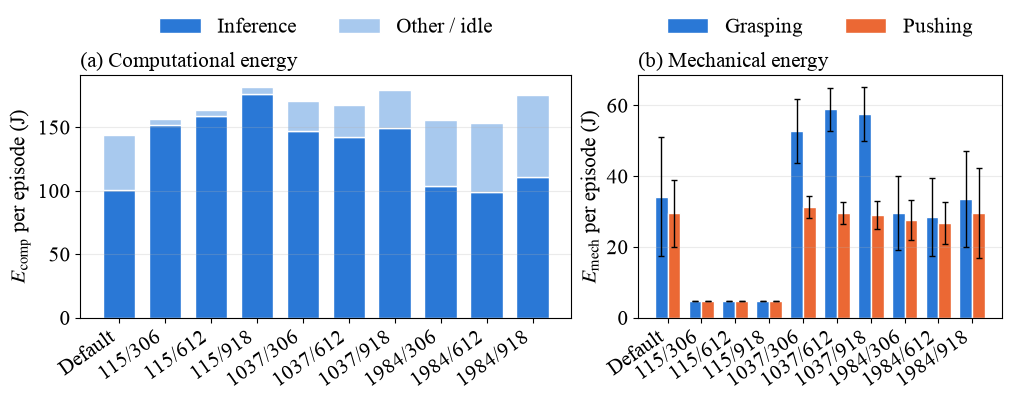

In [212]:
power = pd.read_csv(RUN_DIR / 'power_samples.csv.gz')
power_by_ep = {uid: (g.server_t_s.to_numpy(), g.power_w.to_numpy()) for uid, g in power.groupby('episode_uid')}
active_s = ep.set_index('episode_uid').comp_window_s

def integrate(t, p, a, b):
    if b <= a:
        return 0.0
    m = (t > a) & (t < b)
    tt = np.r_[a, t[m], b]
    pp = np.interp(tt, t, p)
    return np.trapezoid(pp, tt)

rows = []
for uid, r in req.groupby('episode_uid'):
    t, p = power_by_ep[uid]
    w = active_s[uid]
    e_win = integrate(t, p, 0.0, w)
    e_inf = sum(integrate(t, p, max(0.0, s), min(w, f))
                for s, f in zip(r.server_inference_start_s, r.server_inference_end_s))
    rows.append(dict(episode_uid=uid, E_window_j=e_win, E_inf_in_window_j=e_inf))
split = ep.merge(pd.DataFrame(rows), on='episode_uid')
rel = (split.E_window_j / split.computational_energy_j - 1).abs()
print(f'Re-integrated window energy vs logged E_comp: max rel. diff {rel.max():.2e}')
split['E_other_j'] = split.computational_energy_j - split.E_inf_in_window_j
split['inf_share_pct'] = 100 * split.E_inf_in_window_j / split.computational_energy_j
energy_split = split.groupby('configuration')[['computational_energy_j', 'E_inf_in_window_j', 'E_other_j',
                                               'inf_share_pct', 'mechanical_energy_j']].mean().reindex(CONFIGS)
energy_split.to_csv(OUT_DIR / 'energy_split.csv')
display(energy_split.round(2))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.9), layout='constrained', gridspec_kw=dict(width_ratios=[1.35, 1]))
x = np.arange(len(CONFIGS))
labels = [short_label(c) for c in CONFIGS]
ax = axs[0]
ax.bar(x, energy_split.E_inf_in_window_j, width=.7, color='#2a78d6', edgecolor='white', lw=1, label='Inference')
ax.bar(x, energy_split.E_other_j, bottom=energy_split.E_inf_in_window_j, width=.7, color='#a8c9ee',
       edgecolor='white', lw=1, label='Other / idle')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('$E_\\mathrm{comp}$ per episode (J)')
ax.set_title('(a) Computational energy', loc='left')
ax.legend(ncol=2, loc='lower center', bbox_to_anchor=(.5, 1.08), frameon=False)
ax.grid(axis='y', alpha=.25)

ax = axs[1]
w = .38
for k, task in enumerate(TASKS):
    t = per_task[per_task.task == task].set_index('configuration').reindex(CONFIGS)
    sd = ep[ep.task == task].groupby('configuration').mechanical_energy_j.std().reindex(CONFIGS)
    ax.bar(x + (k - .5) * w, t.E_mech_j, w, yerr=sd, color=TASK_COLOR[task], edgecolor='white', lw=1,
           error_kw=dict(elinewidth=1, capsize=2), label=TASK_LABEL[task])
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('$E_\\mathrm{mech}$ per episode (J)')
ax.set_title('(b) Mechanical energy', loc='left')
ax.legend(ncol=2, loc='lower center', bbox_to_anchor=(.5, 1.08), frameon=False)
ax.grid(axis='y', alpha=.25)
save_figure(fig, 'fig_cl_energy_breakdown')

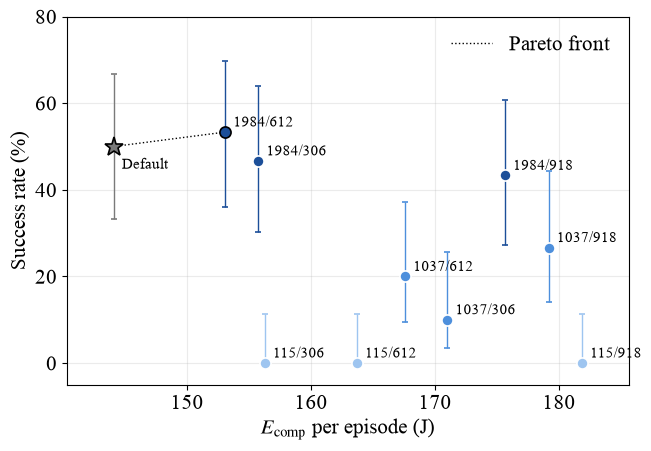

Pareto-optimal: ['Default', '1984/612']


In [213]:
# Trade-off: computational energy per episode vs success rate; Pareto front (min energy, max success).
pc = per_config.set_index(per_config.configuration.astype(str))
front, best = [], -1
for c, row in pc.sort_values(['E_comp_j', 'success_pct'], ascending=[True, False]).iterrows():
    if row.success_pct > best:
        front.append(c); best = row.success_pct
pc['pareto'] = pc.index.isin(front)

fig, ax = plt.subplots(figsize=(6.4, 4.4), layout='constrained')
for c, row in pc.iterrows():
    yerr = [[row.success_pct - row.success_lo_pct], [row.success_hi_pct - row.success_pct]]
    ax.errorbar(row.E_comp_j, row.success_pct, yerr=yerr, fmt='*' if c == REF else 'o',
                ms=14 if c == REF else 8, color=config_color(c), mec='black' if row.pareto else 'white',
                mew=1.2, elinewidth=1, capsize=2, zorder=3)
    ax.annotate(short_label(c), (row.E_comp_j, row.success_pct), xytext=(6, -16) if c == REF else (6, 4),
                textcoords='offset points', fontsize=11)
f = pc.loc[front].sort_values('E_comp_j')
ax.plot(f.E_comp_j, f.success_pct, color='black', lw=1, ls=':', zorder=2, label='Pareto front')
ax.set_xlabel('$E_\\mathrm{comp}$ per episode (J)')
ax.set_ylabel('Success rate (%)')
ax.set_ylim(-5, 80)
ax.margins(x=.1)
ax.grid(alpha=.25)
ax.legend(loc='upper right', frameon=False)
save_figure(fig, 'fig_cl_energy_success_pareto')
print('Pareto-optimal:', [short_label(c) for c in f.index])

Example episode (task, seed, episode): ('grasping', 41, 1)


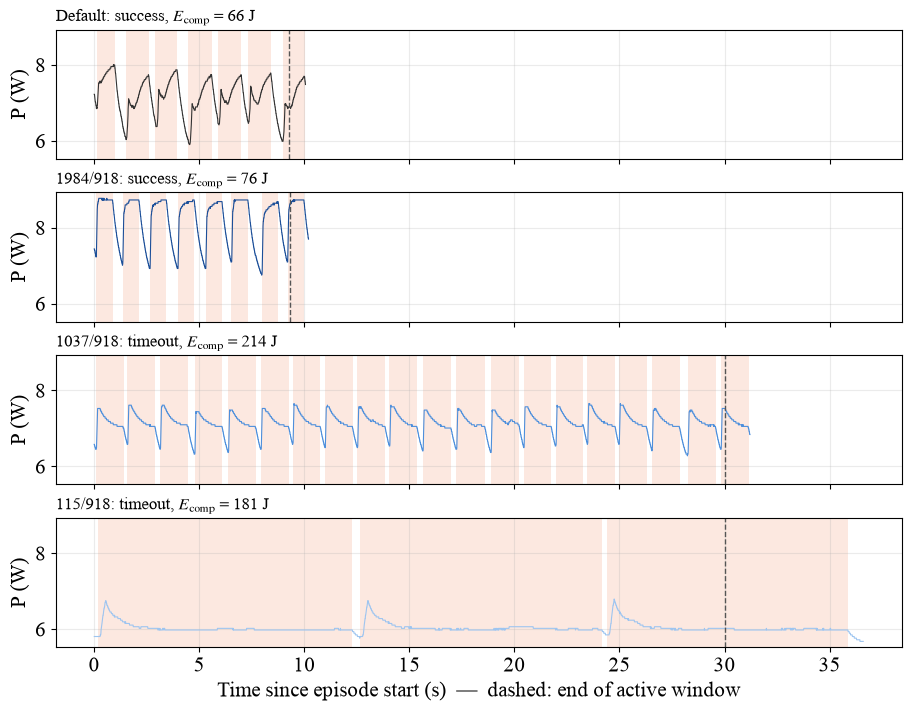

In [214]:
# VDD_IN trace of one episode per CPU level (highest GPU) and the default governor; shaded = inference.
show_cfgs = [REF] + [grid[(grid.cpu_mhz == c) & (grid.gpu_mhz == gpu_order[-1])].index[0] for c in cpu_order[::-1]]
# First grasping episode in which the default governor succeeded (same initial state in every configuration).
ok_ref = ep[(ep.configuration == REF) & (ep.task == 'grasping') & ep.success.astype(bool)].sort_values(['seed', 'episode'])
first = ok_ref.iloc[0] if len(ok_ref) else ep[ep.task == 'grasping'].sort_values(['seed', 'episode']).iloc[0]
example = ('grasping', int(first.seed), int(first.episode))
print('Example episode (task, seed, episode):', example)
fig, axs = plt.subplots(len(show_cfgs), 1, figsize=(9, 1.6 * len(show_cfgs) + .6), sharex=True, sharey=True,
                        layout='constrained')
for ax, c in zip(axs, show_cfgs):
    uid = f'{c}|{example[0]}|{example[1]}|{example[2]}'
    t, p = power_by_ep[uid]
    w = active_s[uid]
    ax.plot(t, p, color=config_color(c) if c != REF else '#333333', lw=.8)
    for s, e_ in req.loc[req.episode_uid == uid, ['server_inference_start_s', 'server_inference_end_s']].to_numpy():
        ax.axvspan(s, e_, color='#eb6834', alpha=.15, lw=0)
    ax.axvline(w, color='#555555', ls='--', lw=1)
    row = ep.set_index('episode_uid').loc[uid]
    ax.set_title(f"{short_label(c)}: {'success' if row.success else 'timeout'}, "
                 f"$E_\\mathrm{{comp}}$ = {row.computational_energy_j:.0f} J", loc='left', fontsize=12)
    ax.set_ylabel('P (W)')
    ax.grid(alpha=.25)
axs[-1].set_xlabel('Time since episode start (s)  —  dashed: end of active window')
save_figure(fig, 'fig_cl_power_traces')

## 6. Paired statistics against the default governor

Pairs share (task, seed, episode), i.e. the same initial cube pose. Success: exact McNemar;
continuous metrics: paired sign-flip permutation with bootstrap 95 % CI (from `analyze_energy.py`).
Holm correction is applied over the 9 grid configurations within each (task, metric).

In [215]:
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

pt = paired.copy()
pt['p_holm'] = pt.groupby(['task', 'metric']).p_value.transform(holm)
pt['configuration'] = pd.Categorical(pt.configuration, CONFIGS, ordered=True)
pt = pt.sort_values(['metric', 'task', 'configuration'])
pt.to_csv(OUT_DIR / 'paired_tests_holm.csv', index=False)
print('Metrics:', pt.metric.unique().tolist())
for metric in ['success', 'computational_energy_j', 'mechanical_energy_j', 'inference_ms_mean']:
    sub = pt[pt.metric == metric]
    if len(sub):
        print(f'\n== {metric} (config − default)')
        display(sub[['configuration', 'task', 'n_pairs', 'diff_mean', 'ci95_low', 'ci95_high',
                     'p_value', 'p_holm', 'test']].round(4))

Metrics: ['computational_energy_j', 'inference_energy_j', 'inference_ms_mean', 'mechanical_energy_j', 'success']

== success (config − default)


,configuration,task,n_pairs,diff_mean,ci95_low,ci95_high,p_value,p_holm,test
10,cpu115.2_gpu306,all,30,-50.0000,NaN,NaN,0.0001,0.0005,exact McNemar
25,cpu115.2_gpu612,all,30,-50.0000,NaN,NaN,0.0001,0.0005,exact McNemar
40,cpu115.2_gpu918,all,30,-50.0000,NaN,NaN,0.0001,0.0005,exact McNemar
55,cpu1036.8_gpu306,all,30,-40.0000,NaN,NaN,0.0075,0.0452,exact McNemar
70,cpu1036.8_gpu612,all,30,-30.0000,NaN,NaN,0.0490,0.2452,exact McNemar
85,cpu1036.8_gpu918,all,30,-23.3333,NaN,NaN,0.1671,0.6683,exact McNemar
100,cpu1984_gpu306,all,30,-3.3333,NaN,NaN,1.0000,1.0000,exact McNemar
115,cpu1984_gpu612,all,30,3.3333,NaN,NaN,1.0000,1.0000,exact McNemar
130,cpu1984_gpu918,all,30,-6.6667,NaN,NaN,0.6875,1.0000,exact McNemar
0,cpu115.2_gpu306,grasping,15,-73.3333,NaN,NaN,0.0010,0.0088,exact McNemar



== computational_energy_j (config − default)


,configuration,task,n_pairs,diff_mean,ci95_low,ci95_high,p_value,p_holm,test
11,cpu115.2_gpu306,all,30,12.1902,-11.8968,36.3600,0.3500,1.0000,paired sign-flip permutation
26,cpu115.2_gpu612,all,30,19.6159,-4.6473,43.8333,0.1399,0.6994,paired sign-flip permutation
41,cpu115.2_gpu918,all,30,37.7750,13.5910,61.9985,0.0090,0.0810,paired sign-flip permutation
56,cpu1036.8_gpu306,all,30,26.9120,-3.7782,56.9166,0.1027,0.6161,paired sign-flip permutation
71,cpu1036.8_gpu612,all,30,23.5099,-8.4176,54.6650,0.1605,0.6994,paired sign-flip permutation
86,cpu1036.8_gpu918,all,30,35.0929,-1.0051,71.4245,0.0673,0.4711,paired sign-flip permutation
101,cpu1984_gpu306,all,30,11.6661,-13.0047,36.1673,0.4346,1.0000,paired sign-flip permutation
116,cpu1984_gpu612,all,30,8.9976,-13.0505,29.9455,0.4190,1.0000,paired sign-flip permutation
131,cpu1984_gpu918,all,30,31.5637,7.2777,56.5673,0.0162,0.1296,paired sign-flip permutation
1,cpu115.2_gpu306,grasping,15,46.7415,9.7905,75.8244,0.0234,0.0936,paired sign-flip permutation



== mechanical_energy_j (config − default)


,configuration,task,n_pairs,diff_mean,ci95_low,ci95_high,p_value,p_holm,test
12,cpu115.2_gpu306,all,30,-27.1911,-32.2493,-22.8233,0.0001,0.0009,paired sign-flip permutation
27,cpu115.2_gpu612,all,30,-27.1911,-32.2196,-22.6768,0.0001,0.0009,paired sign-flip permutation
42,cpu115.2_gpu918,all,30,-27.1911,-32.3025,-22.7624,0.0001,0.0009,paired sign-flip permutation
57,cpu1036.8_gpu306,all,30,10.1965,5.2438,15.2836,0.0009,0.0054,paired sign-flip permutation
72,cpu1036.8_gpu612,all,30,12.3436,5.9873,18.7668,0.0014,0.0070,paired sign-flip permutation
87,cpu1036.8_gpu918,all,30,11.4039,4.7862,18.1081,0.0026,0.0104,paired sign-flip permutation
102,cpu1984_gpu306,all,30,-3.2708,-7.7813,0.4459,0.1370,0.2740,paired sign-flip permutation
117,cpu1984_gpu612,all,30,-4.2719,-8.9563,-0.2059,0.0726,0.2178,paired sign-flip permutation
132,cpu1984_gpu918,all,30,-0.2399,-6.1377,5.6304,0.9441,0.9441,paired sign-flip permutation
2,cpu115.2_gpu306,grasping,15,-29.5705,-38.0104,-22.1130,0.0001,0.0009,paired sign-flip permutation



== inference_ms_mean (config − default)


,configuration,task,n_pairs,diff_mean,ci95_low,ci95_high,p_value,p_holm,test
13,cpu115.2_gpu306,all,30,10813.6693,10755.4870,10870.9910,0.0001,0.0009,paired sign-flip permutation
28,cpu115.2_gpu612,all,30,10877.4390,10793.9525,10962.4449,0.0001,0.0009,paired sign-flip permutation
43,cpu115.2_gpu918,all,30,10814.5467,10746.3396,10883.5580,0.0001,0.0009,paired sign-flip permutation
58,cpu1036.8_gpu306,all,30,511.3735,499.6372,522.5279,0.0001,0.0009,paired sign-flip permutation
73,cpu1036.8_gpu612,all,30,422.6317,410.8736,433.4314,0.0001,0.0009,paired sign-flip permutation
88,cpu1036.8_gpu918,all,30,337.7700,326.1755,348.6155,0.0001,0.0009,paired sign-flip permutation
103,cpu1984_gpu306,all,30,-108.2799,-119.2072,-98.0494,0.0001,0.0009,paired sign-flip permutation
118,cpu1984_gpu612,all,30,-181.7792,-193.1470,-171.5041,0.0001,0.0009,paired sign-flip permutation
133,cpu1984_gpu918,all,30,-203.3486,-214.8816,-192.7318,0.0001,0.0009,paired sign-flip permutation
3,cpu115.2_gpu306,grasping,15,10831.0039,10743.7061,10916.5883,0.0001,0.0009,paired sign-flip permutation


In [216]:
# Main effects across the 3 × 3 grid (Spearman over episodes / requests).
g_ep = ep.dropna(subset=['cpu_mhz_requested'])
g_rq = req.merge(freqs, left_on='configuration', right_index=True).dropna(subset=['cpu_mhz'])
rows = []
for name, df, col in [('inference_ms', g_rq, 'inference_ms'), ('E_inf_j', g_rq, 'inference_energy_j'),
                      ('power_w', g_ep, 'computational_power_w'), ('E_comp_j', g_ep, 'computational_energy_j'),
                      ('E_mech_j', g_ep, 'mechanical_energy_j'), ('success', g_ep, 'success')]:
    for f, fcol in [('CPU', 'cpu_mhz_requested' if df is g_ep else 'cpu_mhz'),
                    ('GPU', 'gpu_mhz_requested' if df is g_ep else 'gpu_mhz')]:
        d = df[[fcol, col]].dropna()
        rho, p = stats.spearmanr(d[fcol], d[col])
        rows.append(dict(metric=name, factor=f, rho=rho, p_value=p, n=len(d)))
display(pd.DataFrame(rows).pivot(index='metric', columns='factor', values=['rho', 'p_value']).round(4))

# GPU effect inside each CPU level (latency, per request).
display(g_rq.groupby(['cpu_mhz', 'gpu_mhz']).inference_ms.agg(['mean', 'std', 'count']).round(1))

rho         p_value        
factor           CPU     GPU     CPU     GPU
metric                                      
E_comp_j      0.1506  0.2775  0.0132  0.0000
E_inf_j      -0.8990  0.0357  0.0000  0.0448
E_mech_j      0.5588  0.0084  0.0000  0.8906
inference_ms -0.8990 -0.4077  0.0000  0.0000
power_w       0.9010  0.3965  0.0000  0.0000
success       0.4692  0.0436  0.0000  0.4751

mean    std  count
cpu_mhz gpu_mhz                       
115.2   306.0    11804.7  282.2     90
        612.0    11868.5  371.2     90
        918.0    11805.6  334.7     90
1036.8  306.0     1502.4   18.3    496
        612.0     1413.8   17.8    486
        918.0     1328.7   15.1    481
1984.0  306.0      882.4    7.9    463
        612.0      809.5    9.0    454
        918.0      788.0    7.9    501

## 7. Key numbers

In [217]:
pc = per_config.set_index(per_config.configuration.astype(str))
ref = pc.loc[REF]
lowcpu = pc[pc.cpu_mhz == cpu_order[0]]
viable = pc[(pc.successes > 0) & (pc.index != REF)]
best_sr = viable.success_pct.idxmax()
best_eps = viable.E_comp_per_success_j.idxmin()
fastest = pc.inference_ms.idxmin()

def pct(a, b):
    return 100 * (a - b) / b

print(f"Default governor: success {ref.success_pct:.1f}% [{ref.success_lo_pct:.1f}, {ref.success_hi_pct:.1f}], "
      f"latency {ref.inference_ms:.0f} ms, P {ref.power_w:.2f} W, E_comp {ref.E_comp_j:.1f} J/episode, "
      f"{ref.E_comp_per_success_j:.0f} J/success")
print(f"CPU {cpu_order[0]:.0f} MHz: latency {lowcpu.inference_ms.min():.0f}–{lowcpu.inference_ms.max():.0f} ms "
      f"(> {HORIZON_MS:.0f} ms horizon in {lowcpu.requests_over_horizon_pct.min():.0f}% of requests), "
      f"success {lowcpu.success_pct.max():.0f}%, E_mech {lowcpu.E_mech_j.mean():.1f} J (arm holds)")
print(f"Fastest: {short_label(fastest)} {pc.loc[fastest, 'inference_ms']:.0f} ms "
      f"({pct(pc.loc[fastest, 'inference_ms'], ref.inference_ms):+.1f}% vs default)")
for c in dict.fromkeys([best_sr, best_eps]):
    r = pc.loc[c]
    print(f"{short_label(c)}: success {r.success_pct:.1f}% [{r.success_lo_pct:.1f}, {r.success_hi_pct:.1f}], "
          f"latency {r.inference_ms:.0f} ms, E_comp {r.E_comp_j:.1f} J ({pct(r.E_comp_j, ref.E_comp_j):+.1f}%), "
          f"E_comp/success {r.E_comp_per_success_j:.0f} J ({pct(r.E_comp_per_success_j, ref.E_comp_per_success_j):+.1f}%), "
          f"E_inf {r.E_inf_j:.2f} J ({pct(r.E_inf_j, ref.E_inf_j):+.1f}%)")
for task in TASKS:
    t = per_task[per_task.task == task].set_index(per_task[per_task.task == task].configuration.astype(str))
    print(f"{TASK_LABEL[task]}: success by config " +
          ', '.join(f"{short_label(c)} {t.loc[c, 'success_pct']:.0f}%" for c in CONFIGS))
print(f"\nNote: {int(ref.episodes)} episodes per configuration ({int(ref.episodes) // 2} per task); "
      "Wilson CIs are wide, compare success with the paired tests above.")

Default governor: success 50.0% [33.2, 66.8], latency 992 ms, P 7.15 W, E_comp 144.1 J/episode, 288 J/success
CPU 115 MHz: latency 11805–11868 ms (> 2500 ms horizon in 100% of requests), success 0%, E_mech 4.7 J (arm holds)
Fastest: 1984/918 788 ms (-20.6% vs default)
1984/612: success 53.3% [36.1, 69.8], latency 809 ms, E_comp 153.1 J (+6.2%), E_comp/success 287 J (-0.4%), E_inf 6.66 J (-8.3%)
Grasping: success by config Default 73%, 115/306 0%, 115/612 0%, 115/918 0%, 1037/306 0%, 1037/612 0%, 1037/918 0%, 1984/306 80%, 1984/612 80%, 1984/918 60%
Pushing: success by config Default 27%, 115/306 0%, 115/612 0%, 115/918 0%, 1037/306 20%, 1037/612 40%, 1037/918 53%, 1984/306 13%, 1984/612 27%, 1984/918 27%

Note: 30 episodes per configuration (15 per task); Wilson CIs are wide, compare success with the paired tests above.
